# Phase 1 (Crawl): Baseline VaR & Expected Shortfall Engine
**Multi-Asset Macro Trading Desk ($10,000,000 Notional | CRO 1-Day 99% VaR Cap = $200,000 | ES Cap = $280,000)**

### Executive Objective
This notebook implements the three foundational risk estimation paradigms at **95%** and **99%** confidence levels over a 1-day holding period and connects them directly to trading desk limit governance:
1. **Plain Historical Simulation (Non-Parametric):** Rolling $n=250$ and $n=500$ lookback windows with non-parametric bootstrap standard errors around the quantile estimate.
2. **Parametric Variance-Covariance Family:** Normal ($\text{VaR}_\alpha^{\text{Norm}}$), Lognormal ($\text{VaR}_\alpha^{\text{Lognorm}}$), MLE Student-$t$ ($\text{VaR}_\alpha^t$), and Cornish-Fisher Semi-Parametric expansion ($z_{\text{CF}}(\alpha)$).
3. **Multivariate Cholesky Monte Carlo Simulation:** Factorizing $\mathbf{\Sigma} = \mathbf{L}\mathbf{L}^\top$ and simulating $M = 10,000$ correlated return scenarios $\mathbf{r}^{(m)} = \boldsymbol{\mu} + \mathbf{L}\mathbf{Z}^{(m)}$.
4. **Coherence & Subadditivity Verification:** Quantifying the multi-asset diversification benefit and proving analytically why Expected Shortfall is a coherent risk measure whereas VaR violates subadditivity on skewed/discrete payoffs.
5. **Pre-Trade Marginal & Incremental VaR Sizing (`TSLA`):** Determining the exact maximum allowable `TSLA` notional addition that keeps the desk within the CRO's USD 200,000 1-Day 99% VaR limit.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path("/Users/mukundankit/Documents/Finance/market_risk_modelling")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_config, prepare_and_save_processed_data
from src.var_estimators import (
    build_phase1_comparison_table,
    compute_subadditivity_and_diversification,
    compute_pretrade_marginal_var_sizing,
)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (13, 5)
plt.rcParams["figure.dpi"] = 120

cfg = load_config()
bundle = prepare_and_save_processed_data(cfg)
arith_returns = bundle["arith_returns"]
portfolio_df = bundle["portfolio"]
weights = cfg["portfolio"]["weights"]
notional_usd = float(cfg["portfolio"]["notional_usd"])
cro_var_limit = float(cfg["governance"]["cro_limits"]["var_99_1d_usd"])
cro_es_limit = float(cfg["governance"]["cro_limits"]["es_99_1d_usd"])

## 1. Comparative Risk Dashboard: 95% and 99% 1-Day VaR & Expected Shortfall
Below we evaluate all seven Phase 1 estimators as of the end of the sample window and benchmark them against the CRO's **USD 200,000 99% VaR** and **USD 280,000 99% ES** limits.

In [2]:
comp_table = build_phase1_comparison_table(
    arith_returns,
    portfolio_df,
    weights=weights,
    notional_usd=notional_usd,
    cro_var_99_limit=cro_var_limit,
    cro_es_99_limit=cro_es_limit,
)
comp_table.round(2)

,Estimator,Confidence,VaR_USD,VaR_pct_NAV,ES_USD,ES_pct_NAV,Bootstrap_SE_USD,CRO_VaR_Limit_Breach,CRO_ES_Limit_Breach
0,Historical Simulation (250d),95%,109065.89,1.09,135950.71,1.36,9587.75,False,False
1,Historical Simulation (500d),95%,88660.47,0.89,119078.16,1.19,7364.35,False,False
2,Parametric Normal (Var-Cov),95%,107375.33,1.07,134340.75,1.34,NaN,False,False
3,Parametric Lognormal,95%,106957.87,1.07,133558.42,1.34,NaN,False,False
4,Parametric Student-t (df=7.3),95%,104793.56,1.05,142364.77,1.42,NaN,False,False
5,Cornish-Fisher Semi-Parametric,95%,102194.62,1.02,134925.79,1.35,NaN,False,False
6,"Cholesky Monte Carlo (M=10,000)",95%,105935.35,1.06,133964.62,1.34,NaN,False,False
7,Historical Simulation (250d),99%,158473.92,1.58,173658.09,1.74,17724.11,False,False
8,Historical Simulation (500d),99%,136136.44,1.36,156722.50,1.57,11805.83,False,False
9,Parametric Normal (Var-Cov),99%,151353.73,1.51,173221.56,1.73,NaN,False,False


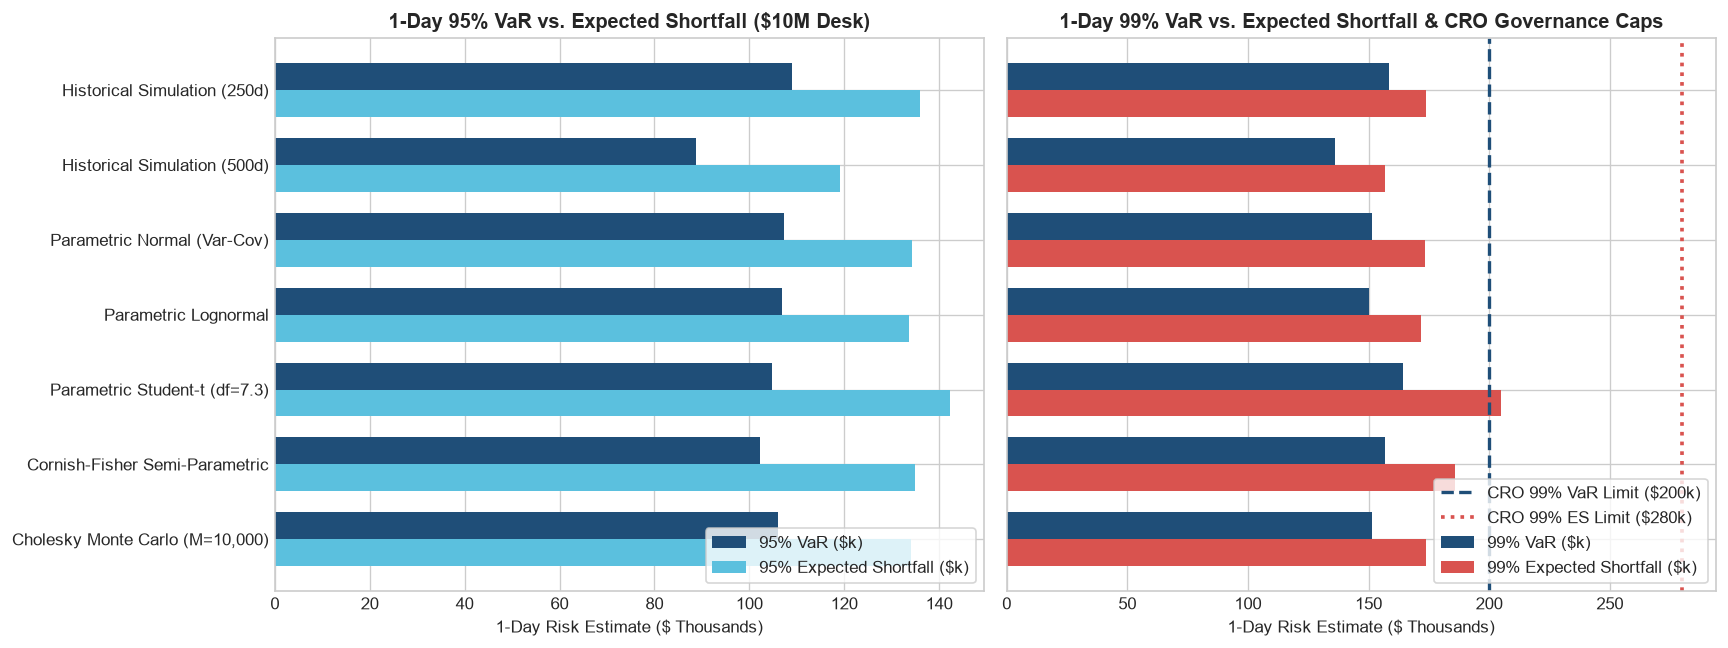

In [3]:
# Visual Comparison of 95% and 99% VaR & ES Across Estimators vs. CRO Limits
df_99 = comp_table[comp_table["Confidence"] == "99%"].copy()
df_95 = comp_table[comp_table["Confidence"] == "95%"].copy()

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.5), sharey=True)

y_pos = np.arange(len(df_95))
bar_h = 0.36

# Left Panel: 95% Confidence Level
axes[0].barh(y_pos - bar_h/2, df_95["VaR_USD"] / 1e3, height=bar_h, color="#1f4e78", label="95% VaR ($k)")
axes[0].barh(y_pos + bar_h/2, df_95["ES_USD"] / 1e3, height=bar_h, color="#5bc0de", label="95% Expected Shortfall ($k)")
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(df_95["Estimator"])
axes[0].invert_yaxis()
axes[0].set_xlabel("1-Day Risk Estimate ($ Thousands)")
axes[0].set_title("1-Day 95% VaR vs. Expected Shortfall ($10M Desk)", fontweight="bold")
axes[0].legend(loc="lower right", frameon=True)

# Right Panel: 99% Confidence Level with CRO Governance Caps
axes[1].barh(y_pos - bar_h/2, df_99["VaR_USD"] / 1e3, height=bar_h, color="#1f4e78", label="99% VaR ($k)")
axes[1].barh(y_pos + bar_h/2, df_99["ES_USD"] / 1e3, height=bar_h, color="#d9534f", label="99% Expected Shortfall ($k)")
axes[1].axvline(cro_var_limit / 1e3, color="#1f4e78", ls="--", lw=2.0, label=f"CRO 99% VaR Limit (${cro_var_limit/1e3:.0f}k)")
axes[1].axvline(cro_es_limit / 1e3, color="#d9534f", ls=":", lw=2.2, label=f"CRO 99% ES Limit (${cro_es_limit/1e3:.0f}k)")
axes[1].set_xlabel("1-Day Risk Estimate ($ Thousands)")
axes[1].set_title("1-Day 99% VaR vs. Expected Shortfall & CRO Governance Caps", fontweight="bold")
axes[1].legend(loc="lower right", frameon=True)

plt.tight_layout()
plt.show()

## 2. Coherence, Diversification Benefit & Subadditivity Verification
A risk measure $\rho(\cdot)$ is **coherent** (Artzner et al., 1999) if it satisfies Monotonicity, Translation Invariance, Positive Homogeneity, and **Subadditivity**:
$$\rho(L_1 + L_2) \le \rho(L_1) + \rho(L_2)$$
Below we demonstrate:
1. **Multi-Asset Diversification Benefit:** Across our 4-asset desk (`SPY`, `AAPL`, `TLT`, `GLD`), the diversified portfolio VaR and ES are substantially lower than the sum of standalone asset VaRs/ES.
2. **Why VaR Violates Subadditivity on Discrete/Skewed Payoffs while ES Holds:** For two independent credit-sensitive bonds each with a $0.8\%$ default probability of losing $\$100,000$, standalone $99\%$ VaR is $\$0$ for each bond, yet combined portfolio $99\%$ VaR jumps to $\$100,000 > \$0 + \$0$. By contrast, $99\%$ Expected Shortfall satisfies subadditivity ($\text{ES}_{0.99}(L_1+L_2) = \$100,640 \le \$80,000 + \$80,000 = \$160,000$).

In [4]:
div_table, coherence_proof = compute_subadditivity_and_diversification(
    arith_returns, weights=weights, alpha=0.99, notional_usd=notional_usd, lookback_days=250
)
print("--- Discrete Payoff Subadditivity Counterexample (99% Confidence) ---")
for k, v in coherence_proof.items():
    print(f"  {k:32s}: {v}")

div_table.round(2)

--- Discrete Payoff Subadditivity Counterexample (99% Confidence) ---
  var_bond1                       : 0.0
  var_bond2                       : 0.0
  var_sum_standalone              : 0.0
  var_combined_portfolio          : 100000.0
  var_violates_subadditivity      : True
  es_bond1                        : 79999.99999999993
  es_bond2                        : 79999.99999999993
  es_sum_standalone               : 159999.99999999985
  es_combined_portfolio           : 100640.0
  es_satisfies_subadditivity      : True


,Position,Weight_pct,Allocation_USD,Normal_VaR_99_USD,Normal_ES_99_USD,HS_VaR_99_USD,HS_ES_99_USD
0,SPY,30.0,3000000.0,73391.54,84083.25,75225.00,79103.55
1,AAPL,20.0,2000000.0,74041.82,84975.50,80967.51,89988.81
2,TLT,30.0,3000000.0,54959.73,62722.78,63287.38,66759.68
3,GLD,20.0,2000000.0,37267.71,42610.29,48228.85,50775.32
4,Undiversified Sum of Standalone,100.0,10000000.0,239660.79,274391.83,267708.73,286627.35
5,Diversified Multi-Asset Portfolio,100.0,10000000.0,151353.73,173221.56,158473.92,173658.09
6,Diversification Benefit ($ Saved),0.0,0.0,88307.06,101170.27,109234.81,112969.26


## 3. Pre-Trade Marginal & Incremental VaR Sizing (`TSLA` Addition)
A portfolio manager proposes adding a volatile `TSLA` equity position on top of the existing USD 10,000,000 book. Using Component/Marginal VaR decomposition and numerical root-finding (`scipy.optimize.brentq`), we determine the exact maximum `TSLA` notional that keeps the desk below the CRO's **USD 200,000 1-Day 99% VaR cap**.

In [5]:
sizing_res = compute_pretrade_marginal_var_sizing(
    arith_returns,
    base_weights=weights,
    candidate_ticker="TSLA",
    base_notional_usd=notional_usd,
    cro_var_99_limit_usd=cro_var_limit,
    alpha=0.99,
    lookback_days=250,
)

print(f"Baseline 1-Day 99% Normal VaR          : ${sizing_res['baseline_normal_var_99_usd']:,.2f}")
print(f"Baseline 1-Day 99% Historical Sim VaR  : ${sizing_res['baseline_hs_var_99_usd']:,.2f}")
print(f"CRO 1-Day 99% VaR Governance Cap       : ${sizing_res['cro_var_99_limit_usd']:,.2f}")
print(f"TSLA Marginal VaR (per $1 added)       : ${sizing_res['tsla_marginal_var_per_dollar']:.4f}")
print(f"Max Allowable TSLA Trade (Normal VaR)  : ${sizing_res['max_allowable_tsla_normal_usd']:,.2f}")
print(f"Max Allowable TSLA Trade (Hist Sim VaR): ${sizing_res['max_allowable_tsla_hs_usd']:,.2f}")

sizing_res["component_var_table"].round(3)

Baseline 1-Day 99% Normal VaR          : $151,353.73
Baseline 1-Day 99% Historical Sim VaR  : $158,473.92
CRO 1-Day 99% VaR Governance Cap       : $200,000.00
TSLA Marginal VaR (per $1 added)       : $0.0397
Max Allowable TSLA Trade (Normal VaR)  : $961,273.98
Max Allowable TSLA Trade (Hist Sim VaR): $765,211.44


,Asset,Position_USD,Marginal_VaR_per_Dollar,Component_VaR_99_USD,Pct_Contribution_to_VaR
0,SPY,3000000.0,0.020,59897.877,39.575
1,AAPL,2000000.0,0.031,61493.986,40.629
2,TLT,3000000.0,0.005,14166.093,9.360
3,GLD,2000000.0,0.008,15795.774,10.436


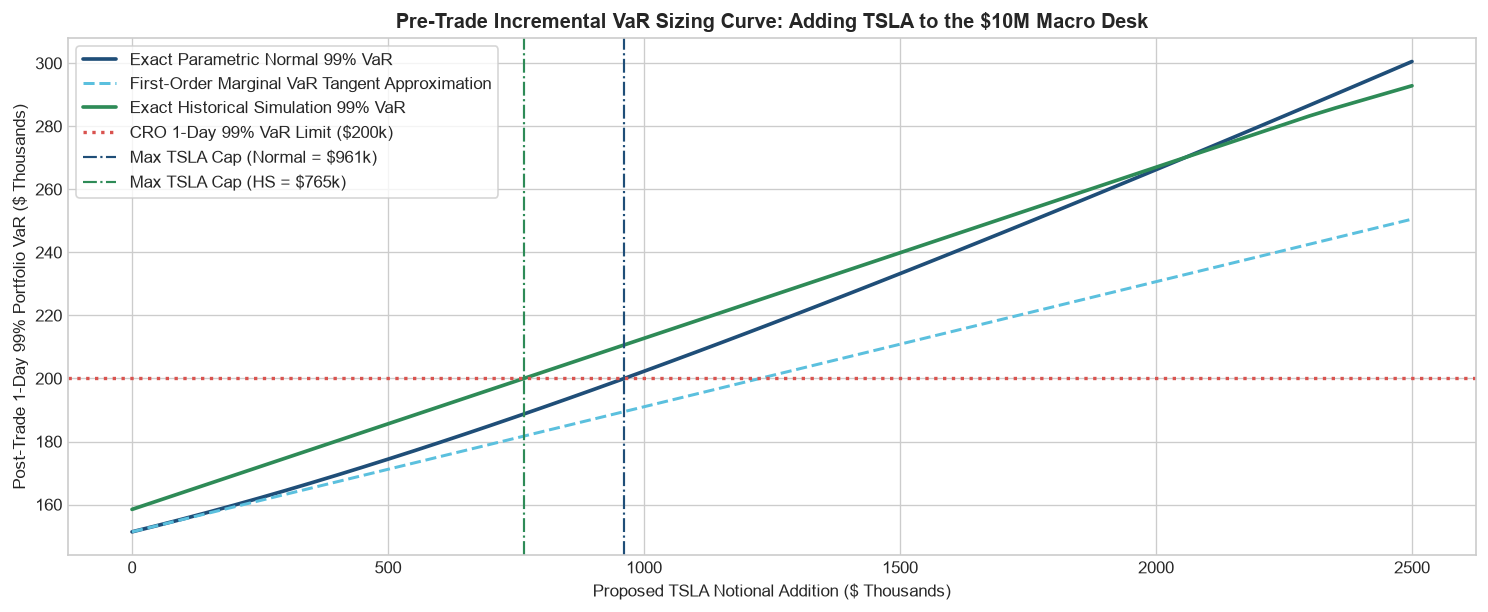

In [6]:
curve_df = sizing_res["sizing_curve_df"]
fig, ax = plt.subplots(figsize=(12.5, 5.2))

ax.plot(curve_df["TSLA_Trade_Size_USD"] / 1e3, curve_df["New_Portfolio_Normal_VaR_99_USD"] / 1e3, color="#1f4e78", lw=2.2, label="Exact Parametric Normal 99% VaR")
ax.plot(curve_df["TSLA_Trade_Size_USD"] / 1e3, curve_df["Linear_Marginal_Approx_VaR_USD"] / 1e3, color="#5bc0de", lw=1.8, ls="--", label="First-Order Marginal VaR Tangent Approximation")
ax.plot(curve_df["TSLA_Trade_Size_USD"] / 1e3, curve_df["New_Portfolio_HS_VaR_99_USD"] / 1e3, color="#2e8b57", lw=2.2, label="Exact Historical Simulation 99% VaR")
ax.axhline(cro_var_limit / 1e3, color="#d9534f", lw=2.0, ls=":", label=f"CRO 1-Day 99% VaR Limit (${cro_var_limit/1e3:.0f}k)")

max_norm_k = sizing_res["max_allowable_tsla_normal_usd"] / 1e3
max_hs_k = sizing_res["max_allowable_tsla_hs_usd"] / 1e3
ax.axvline(max_norm_k, color="#1f4e78", lw=1.3, ls="-.", label=f"Max TSLA Cap (Normal = ${max_norm_k:,.0f}k)")
ax.axvline(max_hs_k, color="#2e8b57", lw=1.3, ls="-.", label=f"Max TSLA Cap (HS = ${max_hs_k:,.0f}k)")

ax.set_title("Pre-Trade Incremental VaR Sizing Curve: Adding TSLA to the $10M Macro Desk", fontweight="bold")
ax.set_xlabel("Proposed TSLA Notional Addition ($ Thousands)")
ax.set_ylabel("Post-Trade 1-Day 99% Portfolio VaR ($ Thousands)")
ax.legend(loc="upper left", frameon=True)
plt.tight_layout()
plt.show()